# Binary Classification For Predictive Maintenance with the AI4I2020 Dataset

## 1. Business Problem & Project Objective

Manufacturing environments operate under a constant pressure to maximize production efficiency; therefore, stoppages due to machine failures can be very harmful to keep production KPIs high. It was, in fact, a recurrent issue during my internship at an OEM supplier for the automotive industry. 

### Project Objective

This project aims to develop a lightweight binary classification model capable of identifying machine failure conditions based on real-time operational measurements, including the following:

- Air Temperature
- Process temperature
- Rotational speed
- Torque
- Tool wear

Given the dataset structure, I will build an XGBoost classifier and a feed-forward multilayer perceptron (MLP) and then compare its results to find the model that works best. Both models will be evaluated using:

- Recall score
- F1 Score
- Average-Precision score

### Limitations

AI4I 2020 is a synthetic dataset generated using predefined failure mechanisms. Results on this dataset demonstrate model development and evaluation workflows, but they do **not** establish that the models will generalize to real industrial equipment. Real-world deployment would require validation on representative operational data, attention to data drift, and assessment of the costs of false alarms and missed failures.



In [1]:
# Fundamental libs
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn pre-processing
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

# Sklearn metrics
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, f1_score,
    precision_score, recall_score, precision_recall_curve,
    average_precision_score
)

# XGBoost
from scipy.stats import randint, uniform, loguniform
from xgboost import XGBClassifier

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import torchmetrics
from torchmetrics.classification import BinaryF1Score, BinaryAveragePrecision

# Optuna
import optuna

In [2]:
# Import the dataset. For reprudicibility you should download the csv file
# and change the path to your actual csv path.
dataset = Path("Datasets/ai4i2020.csv")

df = pd.read_csv(dataset)
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Set UDI as Index. 
df = df.set_index(["UDI"])

## 2. Exploratory Data Analysis (EDA)

The analysis will examine feature distributions, relationships between variables, potential anomalies, and the distribution of the target variable. Visualizations and statistical summaries will be used to identify relevant insights that may influence subsequent data preparation and model development.


In [4]:
# Analyze the features
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 1 to 10000
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Product ID               10000 non-null  object 
 1   Type                     10000 non-null  object 
 2   Air temperature [K]      10000 non-null  float64
 3   Process temperature [K]  10000 non-null  float64
 4   Rotational speed [rpm]   10000 non-null  int64  
 5   Torque [Nm]              10000 non-null  float64
 6   Tool wear [min]          10000 non-null  int64  
 7   Machine failure          10000 non-null  int64  
 8   TWF                      10000 non-null  int64  
 9   HDF                      10000 non-null  int64  
 10  PWF                      10000 non-null  int64  
 11  OSF                      10000 non-null  int64  
 12  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(8), object(2)
memory usage: 1.1+ MB


In [5]:
# Review data quality and ranges
df.describe()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### Failure Modes

The AI4I 2020 dataset identifies five different failure modes:

- **TWF (Tool Wear Failure):** Occurs when the accumulated tool wear reaches a critical threshold
- **HDF (Heat Dissipation Failure):** Occurs when insufficient heat dissipation causes the machine to overheat.
- **PWF (Power Failure):** Occurs when the machine's mechanical power falls outside predefined operating limits. 
- **OSF (Overstrain Failure):** Occurs when the combination of tool wear and torque exceeds a predefined threshold
- **RNF (Random Failure):** Represents randomly occurring failures that are not directly associated with the four previously described failure mechanisms.

Since these are directly correlated with the machine failure, they won't be used as inputs.

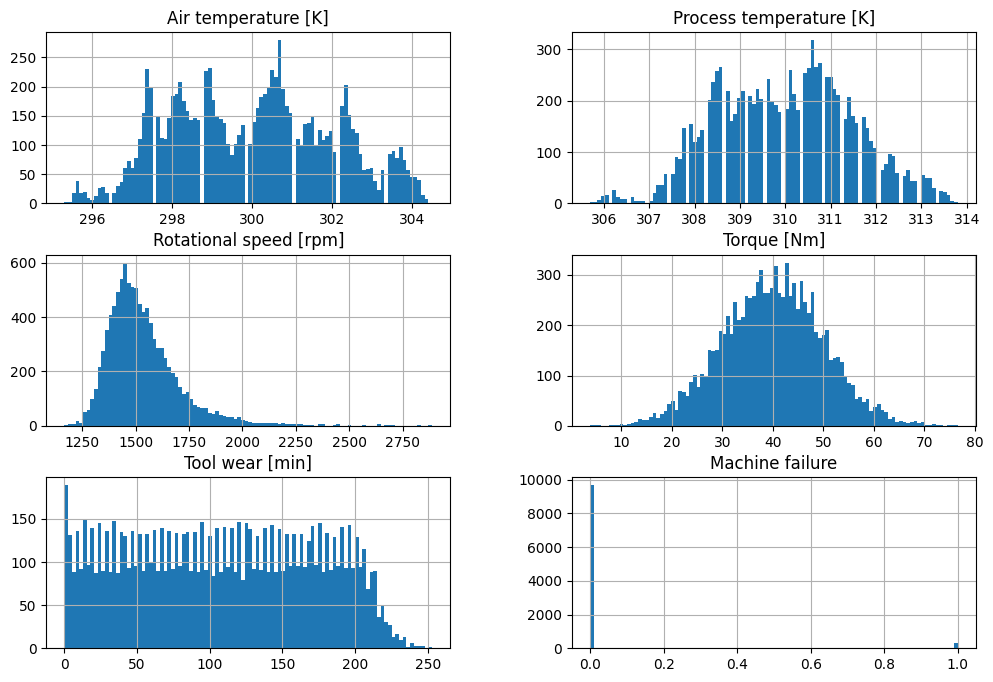

In [6]:
df.drop(columns=["TWF", "HDF", "PWF", "OSF", "RNF"]).hist(
    bins=100,
    figsize=(12, 8)
)

plt.show()

The histograms suggest that torque and process temperature are approximately normally distributed, while rotational speed is right-skewed. This motivates examining a log transformation of rotational speed during preprocessing.

Meanwhile, data must be further analyzed. A good plot is the boxplot, to actually get a good grasp on the data. So far, some engineered features are already considered, such as:

- Power = Torque * Rotational Speed (Aiming to add a real physical measure) * 2pi / 60
- Temperature difference = Process Temperature - Air Temperature (Understand if the machine was hotter than usual despite the weather)
- Wear/Speed interaction = Tool wear * Rotational Speed (Try to find if the more time of tool wear + high rotational speed caused more failures than usual)

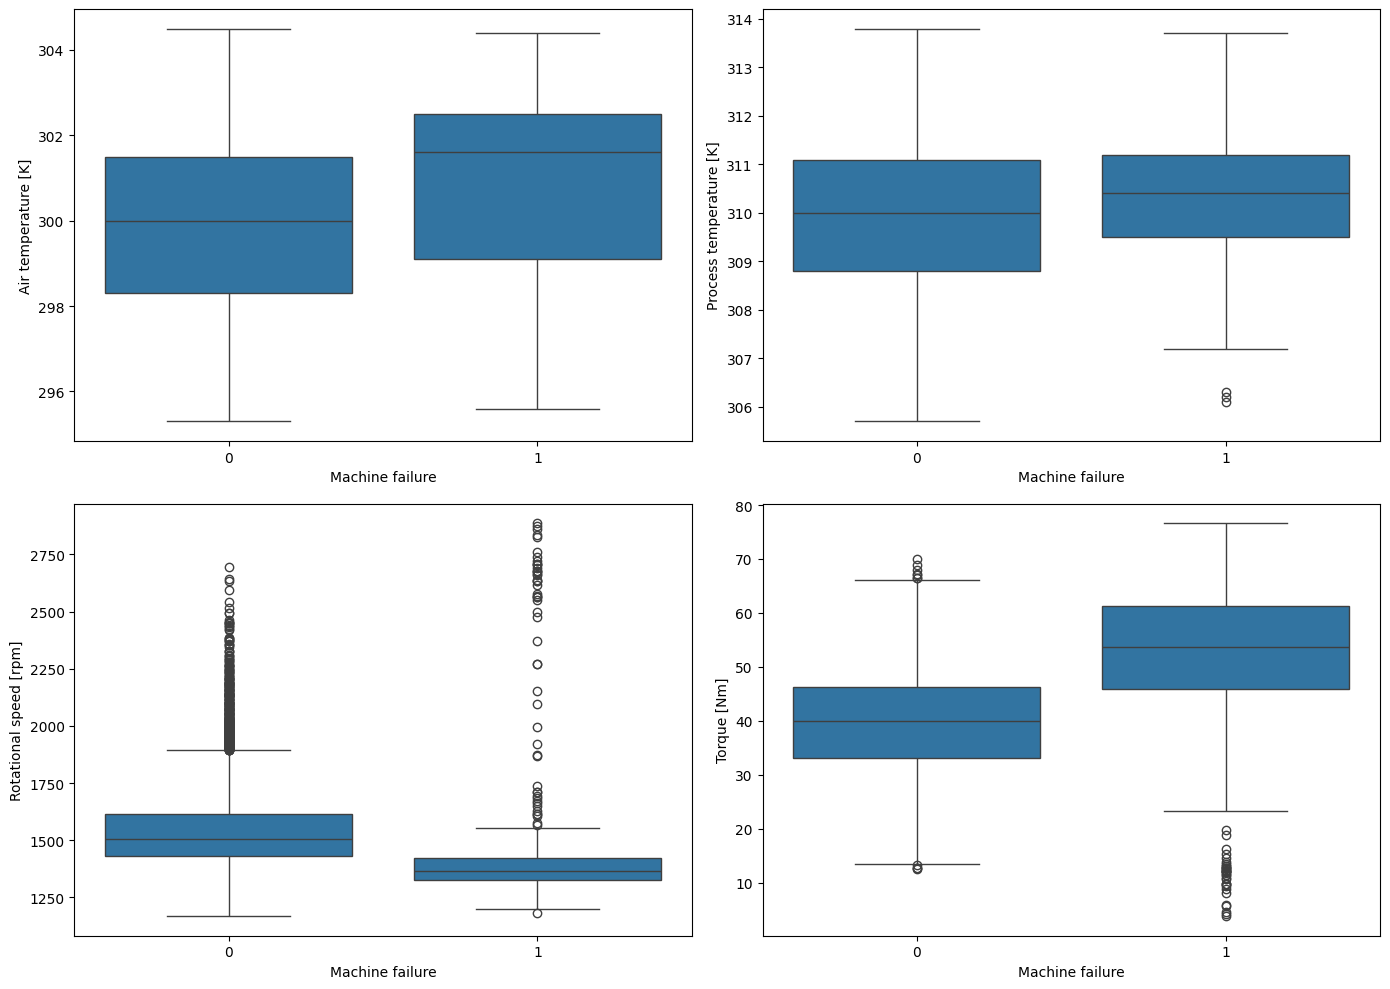

In [7]:
# Boxplots to try to visualize correlations and outliers
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]"
]

for feature, ax in zip(features, axes.flatten()):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=ax
    )

plt.tight_layout()
plt.show()

## 3. Data Preparation
`Product ID` is excluded because it is an identifier rather than an operational measurement. The failure-mode indicators (`TWF`, `HDF`,`PWF`, `OSF`, and `RNF`) are also excluded to prevent target leakage. The target variable is `Machine failure`.

The dataset is split into training, validation and test sets, using a 70 / 15 / 15 split. The stratified splitting ensures the same failure distribution across all the sets.

In [8]:
# Drop columns that the model should not be trained with
# These columns are failure flags. Keeping them would cause data leakage

df = df.drop(columns=["TWF", "HDF", "PWF", "OSF", "RNF", "Product ID"])
X_data = df.drop(columns=["Machine failure"])
y_data = df["Machine failure"]

In [9]:
# Data splits
X_train, X_valid_test, y_train, y_valid_test = train_test_split(X_data, y_data,
                                                                test_size=0.3, stratify=y_data, # stratify the data to get the same distributions
                                                                random_state=42)

X_valid, X_test, y_valid, y_test = train_test_split(X_valid_test, y_valid_test,
                                                    test_size=0.5, stratify=y_valid_test, 
                                                    random_state=42)

In [10]:
# Data Shapes
print(f"X_train shape: {X_train.shape}")
print(f"X_valid shape: {X_valid.shape}")
print(f"X_test shape: {X_test.shape}\n")
print(f"y_train shape: {y_train.shape}")
print(f"y _valid shape: {y_valid.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (7000, 6)
X_valid shape: (1500, 6)
X_test shape: (1500, 6)

y_train shape: (7000,)
y _valid shape: (1500,)
y_test shape: (1500,)


### Pipeline

A complete pipeline is made to be able to transform the train/valid/test sets in one go. The imputer is added just for robustness, even though the dataset does not have missing values. This ensures that even new data with missing values will be predicted by the models. 

The pipeline applies the following transformations:
- **Original numerical features:** median imputation and standardization.
- **Mechanical power:** calculated from torque and rotational speed, then standardized.
- **Temperature difference:** calculated from process temperature minus air temperature, then standardized.
- **Wear–torque interaction:** calculated from tool wear multiplied by torque, then standardized.
- **Rotational speed:** transformed using log1p and standardized.
- **Machine type:** one-hot encoded, with unseen categories ignored during transformation.

This preprocessing pipeline is trained with the training data only to prevent data leakage



In [11]:
# Feature Engineering
def power_feature(X):
    torque = X[:, [0]]
    rpm = X[:, [1]]
    return torque * rpm * (2 * math.pi / 60)


def difference(X):
    return X[:, [0]] - X[:, [1]]


def column_mult(X):
    return X[:, [0]] * X[:, [1]]

# Feature Pipeline
def make_feature_pipeline(function):
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(function),
        StandardScaler()
    )

# Create the feature engineered pipelines
power_pipeline = make_feature_pipeline(power_feature)
difference_pipeline = make_feature_pipeline(difference)
wear_pipeline = make_feature_pipeline(column_mult)

# Log pipeline to fix the distribution
log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"),
    StandardScaler()
)

# Numerical pipeline
default_num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Categorical pipeline
default_cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)

# Original features:
original_features = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)


# Column Transformer
preprocessing = ColumnTransformer([
    ("original", original_features, make_column_selector(dtype_include=np.number)),
    ("Power", power_pipeline, ["Torque [Nm]", "Rotational speed [rpm]"]),
    ("Temp_difference", difference_pipeline, ["Process temperature [K]", "Air temperature [K]"]),
    ("Wear_speed",wear_pipeline,["Tool wear [min]", "Torque [Nm]"]),
    ("log",log_pipeline,["Rotational speed [rpm]"]),
    ("categorical",default_cat_pipeline,make_column_selector(dtype_include=object))
], remainder=default_num_pipeline)


In [12]:
# Convert df to np array
y_train = y_train.to_numpy()

In [13]:
# Learn and transform using the column transformer
X_train_prepared = preprocessing.fit_transform(X_train)

In [14]:
# Verify our feature count
X_train_prepared.shape

(7000, 12)

In [15]:
X_train_prepared

array([[-1.10577932, -1.75941469,  2.01283543, ...,  0.        ,
         0.        ,  1.        ],
       [ 1.84049247,  1.54797328, -1.05555718, ...,  0.        ,
         1.        ,  0.        ],
       [-1.40540018, -1.42192612, -0.2565544 , ...,  0.        ,
         1.        ,  0.        ],
       ...,
       [ 0.14264093,  1.00799157, -0.41746468, ...,  1.        ,
         0.        ,  0.        ],
       [ 0.84175627,  0.80549843, -0.12338727, ...,  0.        ,
         1.        ,  0.        ],
       [-0.65634803, -0.20696728, -0.42856194, ...,  0.        ,
         1.        ,  0.        ]], shape=(7000, 12))

## 4. XGBoost Baseline Model

An XGBoost classifier is trained to establish a strong baseline. This model is expected to perform particularly well, as gradient-boosted decision trees are generally among the top-performing algorithms for tabular datasets such as AI4I2020.

The `scale_pos_weight` parameter is used to penalize the model for misclassifying positive samples (machine failures), encouraging it to achieve higher recall.

The model will then be fine-tuned to further improve its predictive performance.


In [16]:
# Establish a baseline model

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.05,
    max_depth=4, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight= neg / pos,
    random_state=42,
)
xgb.fit(X_train_prepared, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [17]:
# Take a look at the confusion matrix
X_valid_prepared = preprocessing.transform(X_valid)
y_valid = y_valid.to_numpy()

In [18]:
y_pred = xgb.predict(X_valid_prepared)
confusion_matrix(y_valid, y_pred)

array([[1436,   13],
       [   8,   43]])

## 5. Classification Threshold Selection for the Baseline XGBoost Model

In [19]:
y_proba = xgb.predict_proba(X_valid_prepared)[:, 1]

thresholds = np.arange(0.0, 1, 0.05)
print(f"{'Threshold':>7} {'Precision':>10} {'Recall':>4} {'F1':>6} {'FN':>5} {'FP':>4}")

for t in thresholds:
    pred = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    print(f"{t:7.2f} {precision_score(y_valid, pred, zero_division=0):10.3f} "
          f"{recall_score(y_valid, pred):8.3f} {f1_score(y_valid, pred):7.3f} "
          f"{fn:4d} {fp:4d}")

Threshold  Precision Recall     F1    FN   FP
   0.00      0.034    1.000   0.066    0 1449
   0.05      0.439    0.922   0.595    4   60
   0.10      0.529    0.902   0.667    5   41
   0.15      0.600    0.882   0.714    6   30
   0.20      0.625    0.882   0.732    6   27
   0.25      0.652    0.882   0.750    6   24
   0.30      0.672    0.882   0.763    6   22
   0.35      0.692    0.882   0.776    6   20
   0.40      0.717    0.843   0.775    8   17
   0.45      0.754    0.843   0.796    8   14
   0.50      0.768    0.843   0.804    8   13
   0.55      0.796    0.843   0.819    8   11
   0.60      0.788    0.804   0.796   10   11
   0.65      0.804    0.804   0.804   10   10
   0.70      0.800    0.784   0.792   11   10
   0.75      0.816    0.784   0.800   11    9
   0.80      0.816    0.784   0.800   11    9
   0.85      0.830    0.765   0.796   12    8
   0.90      0.848    0.765   0.804   12    7
   0.95      0.860    0.725   0.787   14    6


## 6. Baseline XGBoost Evaluation on the Validation Set

In [20]:
selected_threshold = 0.65

y_pred = (y_proba >= selected_threshold).astype(int)
print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_pred))
print("")
print(f" F1 score: {f1_score(y_valid, y_pred):.2f}")
print(f" Recall: {recall_score(y_valid, y_pred):.2f}")
print(f" Precision: {precision_score(y_valid, y_pred):.2f}")
print(f" AP: {average_precision_score(y_valid, y_proba):.2f}")

Confusion Matrix:
[[1439   10]
 [  10   41]]

 F1 score: 0.80
 Recall: 0.80
 Precision: 0.80
 AP: 0.86


The model results are impressive considering this is the baseline model.

## 7. Fine-Tuned XGBoost Model

Using `RandomizedSearchCV` allows us to explore a broader hyperparameter space within a predefined computational budget. This process may take some time, as `n_iter=1000` combined with 5-fold cross-validation results in a total of 5,000 model fits. 

The search is performed on the CPU, with `n_jobs=-1` to leverage all available CPU cores and parallelize the fitting process. However, on machines with limited computational resources, setting a fixed number of workers may be preferable to avoid excessive CPU utilization and system slowdowns.

In [21]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

xgb_fine = XGBClassifier(random_state=42, eval_metric="aucpr", n_jobs=1)

param_dist = {
    "n_estimators": randint(200, 1000),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 9),
    "min_child_weight": randint(1, 10),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "gamma": uniform(0, 5),
    "reg_alpha": loguniform(1e-4, 10),
    "reg_lambda": loguniform(0.1, 10),
    "scale_pos_weight": uniform((neg / pos) * 0.5, (neg / pos) * 1.5)
}

In [22]:
# ----------------------------
#           WARNING! 
# ----------------------------

# This cell will take a little while to run since it's doing 5k fits
# and uses the CPU to do so.

random_search = RandomizedSearchCV(
    estimator=xgb_fine,
    param_distributions=param_dist,
    n_iter=1000,
    scoring="average_precision",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True
)

random_search.fit(X_train_prepared, y_train)

Fitting 5 folds for each of 1000 candidates, totalling 5000 fits


,estimator,"XGBClassifier...ree=None, ...)"
,param_distributions,"{'colsample_bytree': <scipy.stats....0020C91A97EF0>, 'gamma': <scipy.stats....0020C91A96E10>, 'learning_rate': <scipy.stats....0020C915F52E0>, 'max_depth': <scipy.stats....0020C91AB19A0>, ...}"
,n_iter,1000
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [23]:
print("Best PR-AUC:", random_search.best_score_)
print("Best parameters:", random_search.best_params_)

best_xgb = random_search.best_estimator_

Best PR-AUC: 0.8842423555262815
Best parameters: {'colsample_bytree': np.float64(0.9459979904831105), 'gamma': np.float64(1.6030995327511337), 'learning_rate': np.float64(0.017061399286226887), 'max_depth': 5, 'min_child_weight': 2, 'n_estimators': 242, 'reg_alpha': np.float64(0.001802851780006739), 'reg_lambda': np.float64(0.43765830296755087), 'scale_pos_weight': np.float64(20.045524269847142), 'subsample': np.float64(0.7184707062235994)}


## 8. Classification Threshold Selection for the Fine-Tuned XGBoost Model

In [25]:
y_proba = best_xgb.predict_proba(X_valid_prepared)[:, 1]

thresholds = np.arange(0.0, 1, 0.05)
print(f"{'Threshold':>7} {'Precision':>10} {'Recall':>4} {'F1':>6} {'FN':>5} {'FP':>4}")

for t in thresholds:
    pred = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    print(f"{t:7.2f} {precision_score(y_valid, pred, zero_division=0):10.3f} "
          f"{recall_score(y_valid, pred):8.3f} {f1_score(y_valid, pred):7.3f} "
          f"{fn:4d} {fp:4d}")

Threshold  Precision Recall     F1    FN   FP
   0.00      0.034    1.000   0.066    0 1449
   0.05      0.211    0.980   0.347    1  187
   0.10      0.291    0.980   0.448    1  122
   0.15      0.350    0.961   0.513    2   91
   0.20      0.393    0.941   0.555    3   74
   0.25      0.439    0.922   0.595    4   60
   0.30      0.517    0.902   0.657    5   43
   0.35      0.529    0.902   0.667    5   41
   0.40      0.541    0.902   0.676    5   39
   0.45      0.597    0.902   0.719    5   31
   0.50      0.682    0.882   0.769    6   21
   0.55      0.710    0.863   0.779    7   18
   0.60      0.759    0.863   0.807    7   14
   0.65      0.796    0.843   0.819    8   11
   0.70      0.811    0.843   0.827    8   10
   0.75      0.808    0.824   0.816    9   10
   0.80      0.808    0.824   0.816    9   10
   0.85      0.812    0.765   0.788   12    9
   0.90      0.822    0.725   0.771   14    8
   0.95      0.882    0.588   0.706   21    4


## 9. Fine-Tuned XGBoost Evaluation on the Validation Set

In [26]:
selected_threshold = 0.7

y_pred = (y_proba >= selected_threshold).astype(int)
print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_pred))
print("")
print(f" F1 score: {f1_score(y_valid, y_pred):.2f}")
print(f" Recall: {recall_score(y_valid, y_pred):.2f}")
print(f" Precision: {precision_score(y_valid, y_pred):.2f}")
print(f" AP: {average_precision_score(y_valid, y_proba):.2f}")

Confusion Matrix:
[[1439   10]
 [   8   43]]

 F1 score: 0.83
 Recall: 0.84
 Precision: 0.81
 AP: 0.86


In [27]:
X_test_prepared = preprocessing.transform(X_test)
y_test = y_test.to_numpy()

## 10. Baseline vs. Fine-Tuned XGBoost: Test-Set Evaluation

In [55]:
# BASELINE RESULTS ON THE TEST SET:
baseline_threshold = 0.65
y_test_proba_base = xgb.predict_proba(X_test_prepared)[:, 1]
y_pred_base = (y_test_proba_base >= baseline_threshold).astype(int)
print("Baseline Model's Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_base))
print("")
print(f" F1 score: {f1_score(y_test, y_pred_base):.2f}")
print(f" Recall: {recall_score(y_test, y_pred_base):.2f}")
print(f" Precision: {precision_score(y_test, y_pred_base):.2f}")
print(f" AP: {average_precision_score(y_test, y_test_proba_base):.2f}\n")

# FINE TUNED MODEL RESULTS ON TEST SET:
print("-"*30, end="\n\n")
finetuned_threshold = 0.7
y_test_proba_ftuned = best_xgb.predict_proba(X_test_prepared)[:, 1]
y_pred_ftuned = (y_test_proba_ftuned >= finetuned_threshold).astype(int)
print("Finetuned Model's Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_ftuned))
print("")
print(f" F1 score: {f1_score(y_test, y_pred_ftuned):.2f}")
print(f" Recall: {recall_score(y_test, y_pred_ftuned):.2f}")
print(f" Precision: {precision_score(y_test, y_pred_ftuned):.2f}")
print(f" AP: {average_precision_score(y_test, y_test_proba_ftuned):.2f}\n")

Baseline Model's Confusion Matrix:
[[1444    5]
 [   9   42]]

 F1 score: 0.86
 Recall: 0.82
 Precision: 0.89
 AP: 0.87

------------------------------

Finetuned Model's Confusion Matrix:
[[1443    6]
 [   7   44]]

 F1 score: 0.87
 Recall: 0.86
 Precision: 0.88
 AP: 0.90



## 11. Feed-Forward MLP Model

A feed-forward multilayer perceptron (MLP) is implemented in PyTorch to provide a neural-network comparison with XGBoost. PyTorch also allows the model to use a CUDA-enabled GPU when one is available.

The network is trained on the preprocessed features. Because the target is binary, the model outputs a single logit and is trained with a binary cross-entropy loss with logits. Class weighting is used to account for the imbalance between failure and non-failure observations.

In [86]:
# Check if cuda is available and use it if so
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device being used: {device}")

# Convert to tensors
X_train_tensor = torch.tensor(X_train_prepared, dtype=torch.float32)
X_valid_tensor = torch.tensor(preprocessing.transform(X_valid), dtype=torch.float32)
X_test_tensor  = torch.tensor(preprocessing.transform(X_test), dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_valid_tensor = torch.tensor(y_valid, dtype=torch.float32).reshape(-1, 1)
y_test_tensor  = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

Device being used: cuda


In [87]:
# Create the DataLoaders
g = torch.Generator()
g.manual_seed(42)

train_set = TensorDataset(X_train_tensor, y_train_tensor)
valid_set = TensorDataset(X_valid_tensor, y_valid_tensor)
test_set  = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, generator=g)
valid_loader = DataLoader(valid_set, batch_size=256, generator=g)
test_loader  = DataLoader(test_set, batch_size=256, generator=g)

In [88]:
# Train & eval loop
def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            logits = model(X_batch)
            probs = torch.sigmoid(logits)
            metric.update(probs, y_batch.int())
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs,
         patience=2, factor=0.5, epoch_callback=None):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            probs = torch.sigmoid(logits)
            metric.update(probs.detach(), y_batch.int())
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

In [89]:
torch.manual_seed(42)
n_features = X_train_prepared.shape[1]



model = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(128, 256),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(256, 64),
    nn.ReLU(),
    nn.Dropout(0.1),

    nn.Linear(64, 1)
).to(device)



n_positive = (y_train == 1).sum()
n_negative = (y_train == 0).sum()
pos_weight = n_negative/n_positive
pos_weight = torch.tensor(pos_weight, dtype=torch.float32, device=device)

loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
metric = BinaryAveragePrecision().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
n_epochs = 20

## 12. MLP Training and Classification Threshold Selection

In [90]:
history = train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs)

Epoch 1/20, train loss: 0.8928, train metric: 0.3045, valid metric: 0.4198
Epoch 2/20, train loss: 0.6945, train metric: 0.4290, valid metric: 0.4545
Epoch 3/20, train loss: 0.6163, train metric: 0.4970, valid metric: 0.5845
Epoch 4/20, train loss: 0.5397, train metric: 0.5935, valid metric: 0.6125
Epoch 5/20, train loss: 0.4970, train metric: 0.5966, valid metric: 0.6253
Epoch 6/20, train loss: 0.4618, train metric: 0.5654, valid metric: 0.6759
Epoch 7/20, train loss: 0.4426, train metric: 0.6749, valid metric: 0.6159
Epoch 8/20, train loss: 0.4211, train metric: 0.6976, valid metric: 0.7073
Epoch 9/20, train loss: 0.4295, train metric: 0.6838, valid metric: 0.6350
Epoch 10/20, train loss: 0.4171, train metric: 0.6866, valid metric: 0.6956
Epoch 11/20, train loss: 0.4247, train metric: 0.6385, valid metric: 0.7007
Epoch 12/20, train loss: 0.3951, train metric: 0.7349, valid metric: 0.7187
Epoch 13/20, train loss: 0.3819, train metric: 0.7169, valid metric: 0.6516
Epoch 14/20, train lo

In [91]:
model.eval()
with torch.no_grad():
    logits = model(X_valid_tensor.to(device))
    y_proba = torch.sigmoid(logits).cpu().numpy().ravel()
    y_true = y_valid_tensor.cpu().numpy().ravel()

thresholds = np.arange(0.0, 1, 0.05)
print(f"{'Threshold':>7} {'Precision':>10} {'Recall':>8} {'F1':>7} {'FN':>5} {'FP':>4}")

for t in thresholds:
    pred = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    print(f"{t:7.2f} {precision_score(y_true, pred, zero_division=0):10.3f} "
          f"{recall_score(y_true, pred, zero_division=0):8.3f} "
          f"{f1_score(y_true, pred, zero_division=0):7.3f} "
          f"{fn:5d} {fp:4d}")

Threshold  Precision   Recall      F1    FN   FP
   0.00      0.034    1.000   0.066     0 1449
   0.05      0.127    0.961   0.224     2  338
   0.10      0.158    0.961   0.271     2  261
   0.15      0.176    0.922   0.296     4  220
   0.20      0.193    0.922   0.319     4  197
   0.25      0.212    0.922   0.344     4  175
   0.30      0.230    0.922   0.369     4  157
   0.35      0.251    0.922   0.395     4  140
   0.40      0.264    0.902   0.409     5  128
   0.45      0.298    0.882   0.446     6  106
   0.50      0.321    0.863   0.468     7   93
   0.55      0.355    0.843   0.500     8   78
   0.60      0.387    0.843   0.531     8   68
   0.65      0.413    0.843   0.555     8   61
   0.70      0.460    0.784   0.580    11   47
   0.75      0.542    0.765   0.634    12   33
   0.80      0.650    0.765   0.703    12   21
   0.85      0.691    0.745   0.717    13   17
   0.90      0.783    0.706   0.742    15   10
   0.95      0.769    0.588   0.667    21    9


Results are decent, but not even close to the baseline model. 

## 13. MLP Hyperparameter Optimization with Optuna

Although the baseline MLP did not achieve particularly impressive results, hyperparameter tuning can significantly improve the performance of neural networks. ANNs are particularly sensitive to hyperparameter configurations, making systematic optimization attractive.

For this reason, Optuna is used to explore the hyperparameter space and identify configurations that maximize the model's performance, this time using the F1 score as the metric. Since `pos_weight` is set to be a tunable hyperparameter, optimization will probably be more efficient if the F1 metric is used, as it directly balances precision and recall under class imbalance rather than letting accuracy reward trivial majority-class predictions.

In [92]:
class SeqModel(nn.Module):
    def __init__(self, n_features, n_hidden1, n_hidden2, n_hidden3, n_classes=1, 
                 dropout1=0, dropout2=0, dropout3=0):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(n_features, n_hidden1),
            nn.ReLU(),
            nn.Dropout(dropout1),
        
            nn.Linear(n_hidden1, n_hidden2),
            nn.ReLU(),
            nn.Dropout(dropout2),
        
            nn.Linear(n_hidden2, n_hidden3),
            nn.ReLU(),
            nn.Dropout(dropout3),
        
            nn.Linear(n_hidden3, n_classes)
        )

    def forward(self, X):
        return self.mlp(X)


# Set the hyperparameter space that Optuna will optimize
def objective(trial):
    torch.manual_seed(42)
    torch.cuda.manual_seed_all(42)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-1)
    learning_rate = trial.suggest_float("learning_rate", 1e-3, 1e-1, log=True)
    n_hidden1 = trial.suggest_int("n_hidden1", 20, 300)
    n_hidden2 = trial.suggest_int("n_hidden2", 20, 300)
    n_hidden3 = trial.suggest_int("n_hidden3", 20, 300)
    dropout1 = trial.suggest_float("dropout1", 0, 0.5)
    dropout2 = trial.suggest_float("dropout2", 0, 0.5)
    dropout3 = trial.suggest_float("dropout3", 0, 0.5)
    pos_weight = trial.suggest_float("pos_weight", 0, 3)
    model = SeqModel(n_features=n_features, n_hidden1=n_hidden1, n_hidden2=n_hidden2, n_hidden3=n_hidden3,
                     dropout1=dropout1, dropout2=dropout2, dropout3=dropout3, n_classes=1).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    pos_weight_tensor = torch.tensor([pos_weight], dtype=torch.float32, device=device)
    loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
    metric = BinaryF1Score().to(device)
    best_f1_score = 0.0
    
    for epoch in range(n_epochs):
        history = train(model, optimizer, loss_fn, metric, train_loader, valid_loader, n_epochs=1)
        validation_metric = max(history["valid_metrics"])
        if validation_metric > best_f1_score:
            best_f1_score = validation_metric
        trial.report(validation_metric, epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return best_f1_score
    
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42),
    pruner=optuna.pruners.MedianPruner(
        n_startup_trials=5,
        n_warmup_steps=5
    )
)

study.optimize(objective, n_trials=50, show_progress_bar=True)

[I 2026-11-22 14:26:28,035] A new study created in memory with name: no-name-7e3dbf86-66e7-4211-8d15-5aa35db629d8


  0%|          | 0/50 [00:00<?, ?it/s]

Epoch 1/1, train loss: 0.9735, train metric: 0.0500, valid metric: 0.0000
Epoch 1/1, train loss: 0.2359, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2328, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2330, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2338, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2326, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2327, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2336, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2332, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2333, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2327, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2327, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2319, train metric: 0.0000, valid metric: 0.0000
Epoch 1/1, train loss: 0.2331, train m

In [93]:
study.best_value

0.7835051417350769

In [94]:
study.best_params

{'weight_decay': 0.06557377563422838,
 'learning_rate': 0.0021991980680710083,
 'n_hidden1': 210,
 'n_hidden2': 246,
 'n_hidden3': 87,
 'dropout1': 0.0738027353326299,
 'dropout2': 0.19668244652486164,
 'dropout3': 0.19899349263714317,
 'pos_weight': 1.8453161911149731}

In [95]:
best_params = study.best_params

In [96]:
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Re-create the model with the fine tuned hyperparameters
best_model = SeqModel(n_features=n_features, n_hidden1=best_params["n_hidden1"], 
                      n_hidden2=best_params["n_hidden2"], n_hidden3=best_params["n_hidden3"],
                      dropout1=best_params["dropout1"], dropout2=best_params["dropout2"], 
                      dropout3=best_params["dropout3"], n_classes=1).to(device)
pos_weight = torch.tensor([best_params["pos_weight"]], dtype=torch.float32, device=device)
loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer2 = torch.optim.AdamW(best_model.parameters(), lr=best_params["learning_rate"], 
                              weight_decay=best_params["weight_decay"])
history = train(best_model, optimizer2, loss_fn, metric, train_loader, valid_loader, n_epochs=25)

Epoch 1/25, train loss: 0.1894, train metric: 0.3190, valid metric: 0.3840
Epoch 2/25, train loss: 0.1249, train metric: 0.4901, valid metric: 0.4855
Epoch 3/25, train loss: 0.1154, train metric: 0.5963, valid metric: 0.6309
Epoch 4/25, train loss: 0.1079, train metric: 0.6116, valid metric: 0.6774
Epoch 5/25, train loss: 0.0989, train metric: 0.6883, valid metric: 0.6695
Epoch 6/25, train loss: 0.0981, train metric: 0.6696, valid metric: 0.6217
Epoch 7/25, train loss: 0.0913, train metric: 0.7273, valid metric: 0.6925
Epoch 8/25, train loss: 0.0910, train metric: 0.7396, valid metric: 0.7222
Epoch 9/25, train loss: 0.0938, train metric: 0.7146, valid metric: 0.7090
Epoch 10/25, train loss: 0.0895, train metric: 0.7217, valid metric: 0.7433
Epoch 11/25, train loss: 0.0876, train metric: 0.7368, valid metric: 0.7558
Epoch 12/25, train loss: 0.0855, train metric: 0.7478, valid metric: 0.7733
Epoch 13/25, train loss: 0.0805, train metric: 0.7730, valid metric: 0.7594
Epoch 14/25, train lo

## 14. Classification Threshold Selection for the Fine-Tuned MLP

In [97]:
best_model.eval()
with torch.no_grad():
    y_proba = torch.sigmoid(best_model(X_valid_tensor.to(device))).cpu().numpy().ravel()

thresholds = np.arange(0.0, 1, 0.05)
print(f"{'Threshold':>7} {'Precision':>10} {'Recall':>4} {'F1':>6} {'FN':>5} {'FP':>4}")

for t in thresholds:
    pred = (y_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred).ravel()
    print(f"{t:7.2f} {precision_score(y_valid, pred, zero_division=0):10.3f} "
          f"{recall_score(y_valid, pred):8.3f} {f1_score(y_valid, pred):7.3f} "
          f"{fn:4d} {fp:4d}")

Threshold  Precision Recall     F1    FN   FP
   0.00      0.034    1.000   0.066    0 1449
   0.05      0.372    0.882   0.523    6   76
   0.10      0.526    0.784   0.630   11   36
   0.15      0.655    0.706   0.679   15   19
   0.20      0.702    0.647   0.673   18   14
   0.25      0.762    0.627   0.688   19   10
   0.30      0.789    0.588   0.674   21    8
   0.35      0.857    0.588   0.698   21    5
   0.40      0.857    0.588   0.698   21    5
   0.45      0.900    0.529   0.667   24    3
   0.50      0.929    0.510   0.658   25    2
   0.55      0.923    0.471   0.623   27    2
   0.60      0.920    0.451   0.605   28    2
   0.65      0.958    0.451   0.613   28    1
   0.70      0.958    0.451   0.613   28    1
   0.75      0.947    0.353   0.514   33    1
   0.80      0.933    0.275   0.424   37    1
   0.85      0.929    0.255   0.400   38    1
   0.90      0.900    0.176   0.295   42    1
   0.95      1.000    0.118   0.211   45    0


## 15. Fine-Tuned MLP Evaluation on the Validation Set

In [98]:
selected_threshold = 0.25

y_pred = (y_proba >= selected_threshold).astype(int)
print("Confusion Matrix:")
print(confusion_matrix(y_valid, y_pred))
print("")
print(f" F1 score: {f1_score(y_valid, y_pred):.2f}")
print(f" Recall: {recall_score(y_valid, y_pred):.2f}")
print(f" Precision: {precision_score(y_valid, y_pred):.2f}")
print(f" Precision: {average_precision_score(y_valid, y_proba):.2f}")

Confusion Matrix:
[[1439   10]
 [  19   32]]

 F1 score: 0.69
 Recall: 0.63
 Precision: 0.76
 Precision: 0.76


## 16. Fine-Tuned MLP Evaluation on the Unseen Test Set

In [99]:
with torch.no_grad():
    y_test_proba_mlp = torch.sigmoid(best_model(X_test_tensor.to(device))).cpu().numpy().ravel()

y_pred_mlp = (y_test_proba_mlp >= selected_threshold).astype(int)
print("MLP's Confusion Matrix (test):")
print(confusion_matrix(y_test, y_pred_mlp))
print("")
print(f" F1 score: {f1_score(y_test, y_pred_mlp):.2f}")
print(f" Recall: {recall_score(y_test, y_pred_mlp):.2f}")
print(f" Precision: {precision_score(y_test, y_pred_mlp):.2f}")
print(f" AP: {average_precision_score(y_test, y_test_proba_mlp):.2f}")

MLP's Confusion Matrix (test):
[[1435   14]
 [  16   35]]

 F1 score: 0.70
 Recall: 0.69
 Precision: 0.71
 AP: 0.77


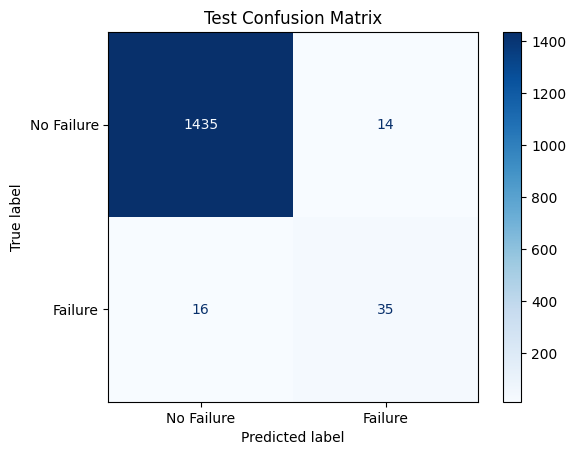

In [100]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_mlp, display_labels=["No Failure", "Failure"], cmap="Blues")
plt.title("Test Confusion Matrix")
plt.show()

## 17. Conclusions

### Results summary

All metrics below are computed on the **unseen test set** (1,500 samples, 51 failures). Thresholds were selected on the validation set only.

| Model | Threshold | Precision | Recall | F1 | FN | FP |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| XGBoost (baseline) | 0.65 | 0.89 | 0.82 | 0.86 | 9 | 5 |
| XGBoost (fine-tuned) | 0.70 | 0.88 | 0.86 | 0.87 | 7 | 6 |
| MLP (fine-tuned) | 0.25 | 0.71 | 0.69 | 0.70 | 16 | 14 |

The fine-tuned XGBoost model achieves the strongest overall test-set F1 score (0.87) and recall (0.86), while maintaining a precision of 0.88. Compared with the baseline, it identifies two additional failures and produces one additional false positive. The fine-tuned MLP performs less strongly on this dataset, with lower precision, recall, and F1.